Цель проекта - оценить финансовую жизнеспособность продукта и cпрогнозировать поведение пользователей на длинной дистанции.

##### Бизнес-задача
Проект решает проблему подписочной модели: окупается ли стоимость привлечения клиента CAC, если он платит небольшую сумму каждый месяц. Чтобы это выяснить, необходимо спрогнозировать ожидаемый срок жизни клиента в продукте Lifetime и его совокупную ценность LTV с учетом вероятности оттока Churn.

Начнём с подготовки данных. Переведем флаг оттока клиентов в бинарный формат для того, чтобы модель его понимала

In [1]:
import pandas as pd
import numpy as np
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)

df['Churn_binary'] = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

df = df.rename(columns={'tenure': 'months'})


Вместо табличного Retention, мы построим математическую кривую дожития - это позволит точнее прогнозировать LTV, так как модель учитывает цензурированные данные (клиентов, которые еще не ушли на момент выгрузки датасета).
Применим модель выживаемости Каплана-Майера

Выведем вероятности удержания на конкретные месяцы - 6, 12, 24


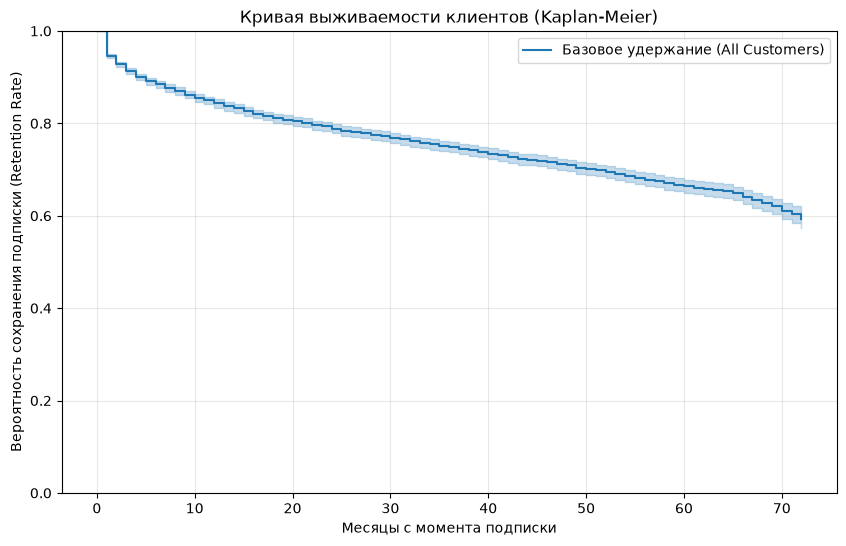

Retention Rate по месяцам:
          Базовое удержание (All Customers)
timeline                                   
6.0                                   0.885
12.0                                  0.843
24.0                                  0.789


In [2]:
kmf = KaplanMeierFitter()

kmf.fit(durations=df['months'], event_observed=df['Churn_binary'], label='Базовое удержание (All Customers)')

plt.figure(figsize=(10, 6))
kmf.plot_survival_function()
plt.title('Кривая выживаемости клиентов (Kaplan-Meier)')
plt.xlabel('Месяцы с момента подписки')
plt.ylabel('Вероятность сохранения подписки (Retention Rate)')
plt.grid(True, alpha=0.3)
plt.ylim([0, 1])
plt.show()

print("Retention Rate по месяцам:")
print(kmf.survival_function_.loc[[6, 12, 24]].round(3))

График отображает вероятность сохранения подписки в зависимости от количества месяцев с момента её оформления

Через 6 месяцев вероятность сохранения подписки составляет 88.5%, через 12 месяцев она снижается до 84.3%, через 24 месяца падает до 78.9%.

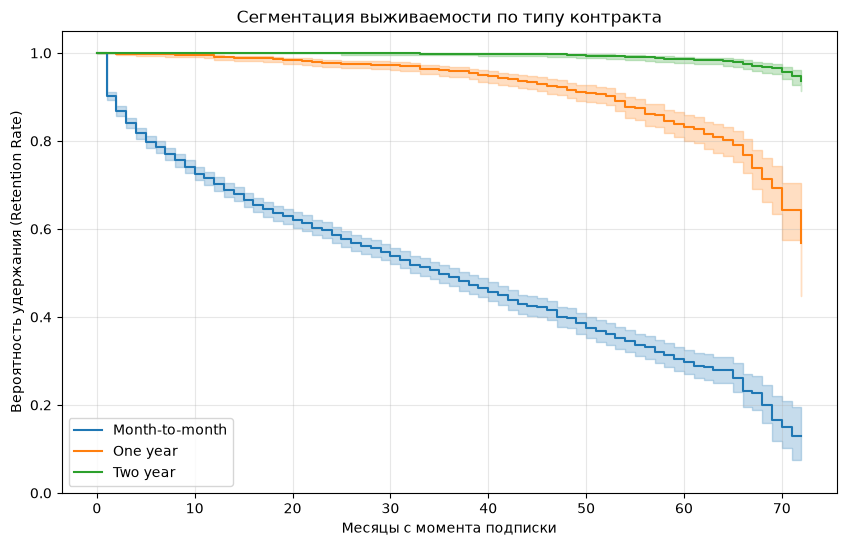

In [3]:
plt.figure(figsize=(10, 6))

contract_types = df['Contract'].unique()

for contract in contract_types:
    mask = df['Contract'] == contract
    kmf = KaplanMeierFitter()
    
    kmf.fit(
        durations=df.loc[mask, 'months'], 
        event_observed=df.loc[mask, 'Churn_binary'], 
        label=contract
    )
    kmf.plot_survival_function()

plt.title('Сегментация выживаемости по типу контракта')
plt.xlabel('Месяцы с момента подписки')
plt.ylabel('Вероятность удержания (Retention Rate)')
plt.grid(True, alpha=0.3)
plt.ylim([0, 1.05])
plt.show()

График отражает разницу в скорости оттока клиентов в зависимости от длительности заключенного контракта.

Помесячная оплата характеризуется самым резким и стабильным оттоком - к 70-му месяцу вероятность удержания падает ниже 20%.


Годовой контракт: удержание остается высоким в первые годы, но после 40 месяцев начинается заметное снижение, достигая уровня около 60% к концу графика.


Двухлетний контракт показывает максимальную лояльность аудитории, сохраняя вероятность удержания выше 90% на протяжении всего наблюдаемого периода.



В итоге:
помесячные тарифы генерируют основной объем оттока. Для максимизации LTV бизнесу необходимо сфокусировать маркетинг на переводе клиентов с тарифа Month-to-month на долгосрочные контракты. Площадь под зеленой и оранжевой кривыми показывает, что возросший ожидаемый срок жизни клиента Expected Lifetime компенсирует бизнесу предоставление скидок на годовые тарифы.

In [4]:
MARGIN = 0.70

ltv_metrics = []
contract_types = df['Contract'].unique()

for contract in contract_types:
    mask = df['Contract'] == contract
    cohort = df[mask]
    
    kmf = KaplanMeierFitter()
    kmf.fit(durations=cohort['months'], event_observed=cohort['Churn_binary'])
    
    expected_lifetime = kmf.survival_function_['KM_estimate'].sum()
    
    arpu = cohort['MonthlyCharges'].mean()
    
    ltv = expected_lifetime * arpu * MARGIN
    
    ltv_metrics.append({
        'Контракт': contract,
        'Expected Lifetime (мес.)': round(expected_lifetime, 1),
        'ARPU ($)': round(arpu, 2),
        'LTV ($)': round(ltv, 2)
    })

df_ltv = pd.DataFrame(ltv_metrics).sort_values('LTV ($)', ascending=False)
print(df_ltv.to_string(index=False))

      Контракт  Expected Lifetime (мес.)  ARPU ($)  LTV ($)
      Two year                      72.5     60.77  3083.08
      One year                      67.0     65.05  3050.12
Month-to-month                      36.4     66.40  1693.08


Вывод по полученным цифрам: тариф с самым высоким средним чеком приносит бизнесу наименьшую итоговую выручку из-за быстрого оттока.

Сегмент Two year имеет самый низкий ежемесячный платеж ARPU $60.77, но за счет максимального ожидаемого срока жизни 72.5 мес. генерирует самый высокий LTV - $3083.08.


Клиенты на тарифе Month-to-month платят больше всего в месяц, $66.40, однако живут в продукте в два раза меньше 36.4 мес., принося лишь $1693.08 LTV.

Перевод пользователя с помесячной оплаты на годовой контракт увеличивает его пожизненную ценность почти в два раза - с $1693.08 до $3050.12, даже при снижении чека до $65.05.


То есть компании выгодно давать скидки за долгосрочные обязательства.

Построим таблицу сводной юнит-экономики с учетом стоимости привлечения

Добавим синтетический САС

In [5]:
cac_mapping = {
    'Month-to-month': 60,
    'One year': 150,
    'Two year': 250
}
df_ltv['CAC ($)'] = df_ltv['Контракт'].map(cac_mapping)

df_ltv['LTV/CAC Ratio'] = (df_ltv['LTV ($)'] / df_ltv['CAC ($)']).round(2)

df_ltv['Payback Period (мес.)'] = (df_ltv['CAC ($)'] / (df_ltv['ARPU ($)'] * MARGIN)).round(1)

df_ltv['Status'] = df_ltv['LTV/CAC Ratio'].apply(lambda x: 'Profitable' if x >= 3 else 'At Risk')

print(df_ltv.to_string(index=False))

      Контракт  Expected Lifetime (мес.)  ARPU ($)  LTV ($)  CAC ($)  LTV/CAC Ratio  Payback Period (мес.)     Status
      Two year                      72.5     60.77  3083.08      250          12.33                    5.9 Profitable
      One year                      67.0     65.05  3050.12      150          20.33                    3.3 Profitable
Month-to-month                      36.4     66.40  1693.08       60          28.22                    1.3 Profitable


Помесячный тариф окупается за 1.3 месяца, а двухлетний - за 5.9 месяцев. Длинные контракты замораживают рекламный бюджет на более длительный срок.

Помесячный тариф показывает наибольшую относительную эффективность 28.22 благодаря низкому CAC в $60.


Хотя помесячный тариф окупается быстрее и имеет лучший коэффициент, в абсолютных деньгах он приносит бизнесу почти в два раза меньше выручки - $1693.08 против $3083.08 у двухлетнего тарифа.


Запас прочности у длинных контрактов - 12.33 и 20.33 - указывает на то, что компания может позволить себе тратить больше на привлечение. Бизнес имеет пространство для увеличения CAC - повышение ставок в рекламе, запуск дорогих промо-кампаний, чтобы агрессивно переводить клиентскую базу на долгосрочные тарифы и наращивать абсолютную прибыль без риска уйти в минус.

В ячейке ниже рассчитаем безопасный коридор скидок для перевода пользователей на долгосрочные тарифы. Посмотрим точные границы для проведения агрессивных маркетинговых кампаний.

In [6]:
MIN_RATIO = 3.0
strategies = []

for contract in ['One year', 'Two year']:
    cac = df_ltv.loc[df_ltv['Контракт'] == contract, 'CAC ($)'].values[0]
    lifetime = df_ltv.loc[df_ltv['Контракт'] == contract, 'Expected Lifetime (мес.)'].values[0]
    current_arpu = df_ltv.loc[df_ltv['Контракт'] == contract, 'ARPU ($)'].values[0]
    
    min_ltv = cac * MIN_RATIO
    
    min_arpu = min_ltv / (lifetime * MARGIN)
    
    max_discount_usd = current_arpu - min_arpu
    max_discount_pct = (max_discount_usd / current_arpu) * 100
    
    strategies.append({
        'Целевой контракт': contract,
        'Текущий ARPU ($)': current_arpu,
        'Мин. ARPU ($)': round(min_arpu, 2),
        'Макс. скидка ($)': round(max_discount_usd, 2),
        'Макс. скидка (%)': round(max_discount_pct, 1)
    })

df_strategy = pd.DataFrame(strategies)
print(df_strategy.to_string(index=False))

Целевой контракт  Текущий ARPU ($)  Мин. ARPU ($)  Макс. скидка ($)  Макс. скидка (%)
        One year             65.05           9.59             55.46              85.2
        Two year             60.77          14.78             45.99              75.7


##### Продуктовые инсайты: 



Для перевода клиента на годовой контракт компания может снизить ежемесячный платеж с $65.05 вплоть до $9.59 - то есть размер максимальной скидки - 85.2%. Даже при таком сильном падении чека когорта останется рентабельной и выполнит норматив LTV/CAC = 3.

У годового контракта запас больше, чем у двухлетнего - 85.2% против 75.7%: разница обусловлена стоимостью привлечения CAC. Привлечение на двухлетний контракт стоит $250, на годовой - $150. Меньший стартовый долг позволяет дать более высокую  относительную скидку на первый год.

Предлагаемая бизнес-стратегия: маркетинговый отдел может запускать офферы формата «Скидка 50% на годовую подписку». Математическое ожидание жизни клиента в 67 месяцев с избытком компенсирует временное снижение ARPU. Бизнес снизит общий Churn Rate, переведя нестабильных клиентов с помесячных тарифов на долгосрочные тарифы.